# How path construction changes performance estimates

This native Julia companion preserves the public data, six time groups, two test groups, one-percent embargo, five paths and scaled C=1 logistic model. Saved public seed-15 bootstrap draws and member seeds supply the bagging randomness; fitting and path assembly execute in Julia. Standardization is unweighted within each full training split, and bagged logistic fits use bootstrap multiplicities, matching the public estimator. Adaptive boundaries retain the original full-sample volatility quantiles and subsplit rule. Observation positions are one-based, and outputs are saved under `outputs/julia`.

A bagged fit averages predicted probabilities from repeated fits inside each combinatorial split:

$$
\widehat p_s(x)=\frac{1}{B}\sum_{b=1}^{B}\widehat p_{s,b}(x).
$$

Here, $s$ identifies a combinatorial split, $B$ is the number of fitted members, $\widehat p_{s,b}(x)$ is member $b$'s predicted probability for input $x$, and $\widehat p_s(x)$ is their average.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("17_combinatorial_purged_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "comparison"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter15-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

using Combinatorics: combinations
using RiskLabAI.Validation: CombinatorialPurgedCV,BaggedCombinatorialPurgedCV,AdaptiveCombinatorialPurgedCV,backtest_paths,get_n_splits
@assert count_observations==2951 && size(public_x)==(2951,6)
external_feature = public_x[:,3]
state_colors = [palette.grid,palette.cyan,palette.rose,palette.amber]
path_colors = [palette.background,palette.cyan,palette.amber,palette.green,palette.rose,violet]

function categorical_legend!(figure,colors,labels)
    for (color,label) in zip(colors,labels)
        plot!(figure,[NaN],[NaN];color,marker=:rect,linewidth=3,label)
    end
    plot!(figure;colorbar=false,legend=:outerright)
    return figure
end

function save_matrix(values,name)
    frame = DataFrame(values,:auto)
    insertcols!(frame,1,:row=>collect(1:size(values,1)))
    save_data(frame,paths,name)
    return nothing
end

function path_scores(method,predictions)
    rows = NamedTuple[]
    for number in sort(collect(keys(predictions)))
        values = predictions[number]
        push!(rows,(method=method,path=number,predictions=length(values),correct=sum(values.==public_y),accuracy=mean(values.==public_y),positive_share=mean(values.==1)))
    end
    result = DataFrame(rows)
    rename!(result,["Method","Path","Predictions","Correct predictions","Accuracy","Positive prediction share"])
    return result
end

function fit_paths(validator,name;sample_indices=nothing,feature_indices=nothing,estimator_seeds=nothing)
    members = validator isa BaggedCombinatorialPurgedCV ? validator.n_estimators : 1
    records,models = NamedTuple[],BookEstimators.LogisticModel[]
    data_positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    @assert length(data_positions)==count_observations
    fit_callback = function(seed,x,y,weights)
        fit_number = length(records)+1
        split,member = cld(fit_number,members),mod1(fit_number,members)
        model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,standardize=true,class_weight=nothing,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,model)
        fields = Dict{Symbol,Any}(:split=>split,:member=>member,:seed=>seed,:training_observations=>length(y),:weight_sum=>sum(weights),:positive_weights=>count(>(0),weights),:intercept=>model.intercept,:objective=>model.objective,:gradient_norm=>model.gradient_norm,:iterations=>model.iterations,:converged=>model.converged)
        for index in 1:6
            fields[Symbol("b",index)] = model.coefficients[index]
            fields[Symbol("center",index)] = model.scaler.center[index]
            fields[Symbol("scale",index)] = model.scaler.scale[index]
        end
        keys_order = [:split,:member,:seed,:training_observations,:weight_sum,:positive_weights,:intercept,:objective,:gradient_norm,:iterations,:converged]
        append!(keys_order,[Symbol(prefix,index) for prefix in ["b","center","scale"] for index in 1:6])
        push!(records,NamedTuple{Tuple(keys_order)}(Tuple(fields[key] for key in keys_order)))
        save_data(DataFrame(position=[data_positions[Tuple(row)] for row in eachrow(x)],weight=weights),paths,name*"_fit_"*string(fit_number)*"_weights")
        return model
    end
    predictions = if members==1
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=identity,fit_estimator=fit_callback,predict=BookEstimators.predict)
    else
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=(_,seed)->seed,fit_estimator=fit_callback,predict=BookEstimators.predict,predict_proba=BookEstimators.predict_proba,estimator_classes=model->model.classes,fit_sample_weights=true,sample_indices,feature_indices,estimator_seeds)
    end
    save_data(DataFrame(records),paths,name*"_fits")
    evidence = DataFrame(position=collect(1:count_observations),date=dates,actual=public_y)
    for number in sort(collect(keys(predictions)))
        evidence[!,"path_"*string(number)] = predictions[number]
    end
    save_data(evidence,paths,name*"_predictions")
    save_splits(name,cv_split(validator))
    return predictions,models
end


fit_paths (generic function with 1 method)

## Public Path Predictions

Row,Method,Path,Predictions,Correct predictions,Accuracy,Positive prediction share
,String,Int64,Int64,Int64,Float64,Float64
1,Standard CPCV,1,2951,1454,0.492714,0.408336
2,Standard CPCV,2,2951,1505,0.509997,0.678414
3,Standard CPCV,3,2951,1476,0.500169,0.808878
4,Standard CPCV,4,2951,1448,0.490681,0.849543
5,Standard CPCV,5,2951,1472,0.498814,0.755337


Row,Method,Path,Predictions,Correct predictions,Accuracy,Positive prediction share
,String,Int64,Int64,Int64,Float64,Float64
1,Standard CPCV,1,2951,1454,0.492714,0.408336
2,Standard CPCV,2,2951,1505,0.509997,0.678414
3,Standard CPCV,3,2951,1476,0.500169,0.808878
4,Standard CPCV,4,2951,1448,0.490681,0.849543
5,Standard CPCV,5,2951,1472,0.498814,0.755337
6,Bagged CPCV,1,2951,1458,0.49407,0.383938
7,Bagged CPCV,2,2951,1504,0.509658,0.663165
8,Bagged CPCV,3,2951,1471,0.498475,0.786852
9,Bagged CPCV,4,2951,1468,0.497458,0.833955


Row,Method,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy
,String,Float64,Float64,Float64,Float64
1,Standard CPCV,0.498475,0.00757732,0.490681,0.509997
2,Bagged CPCV,0.499763,0.00586643,0.49407,0.509658
3,Adaptive CPCV,0.49468,0.00560619,0.488987,0.50288


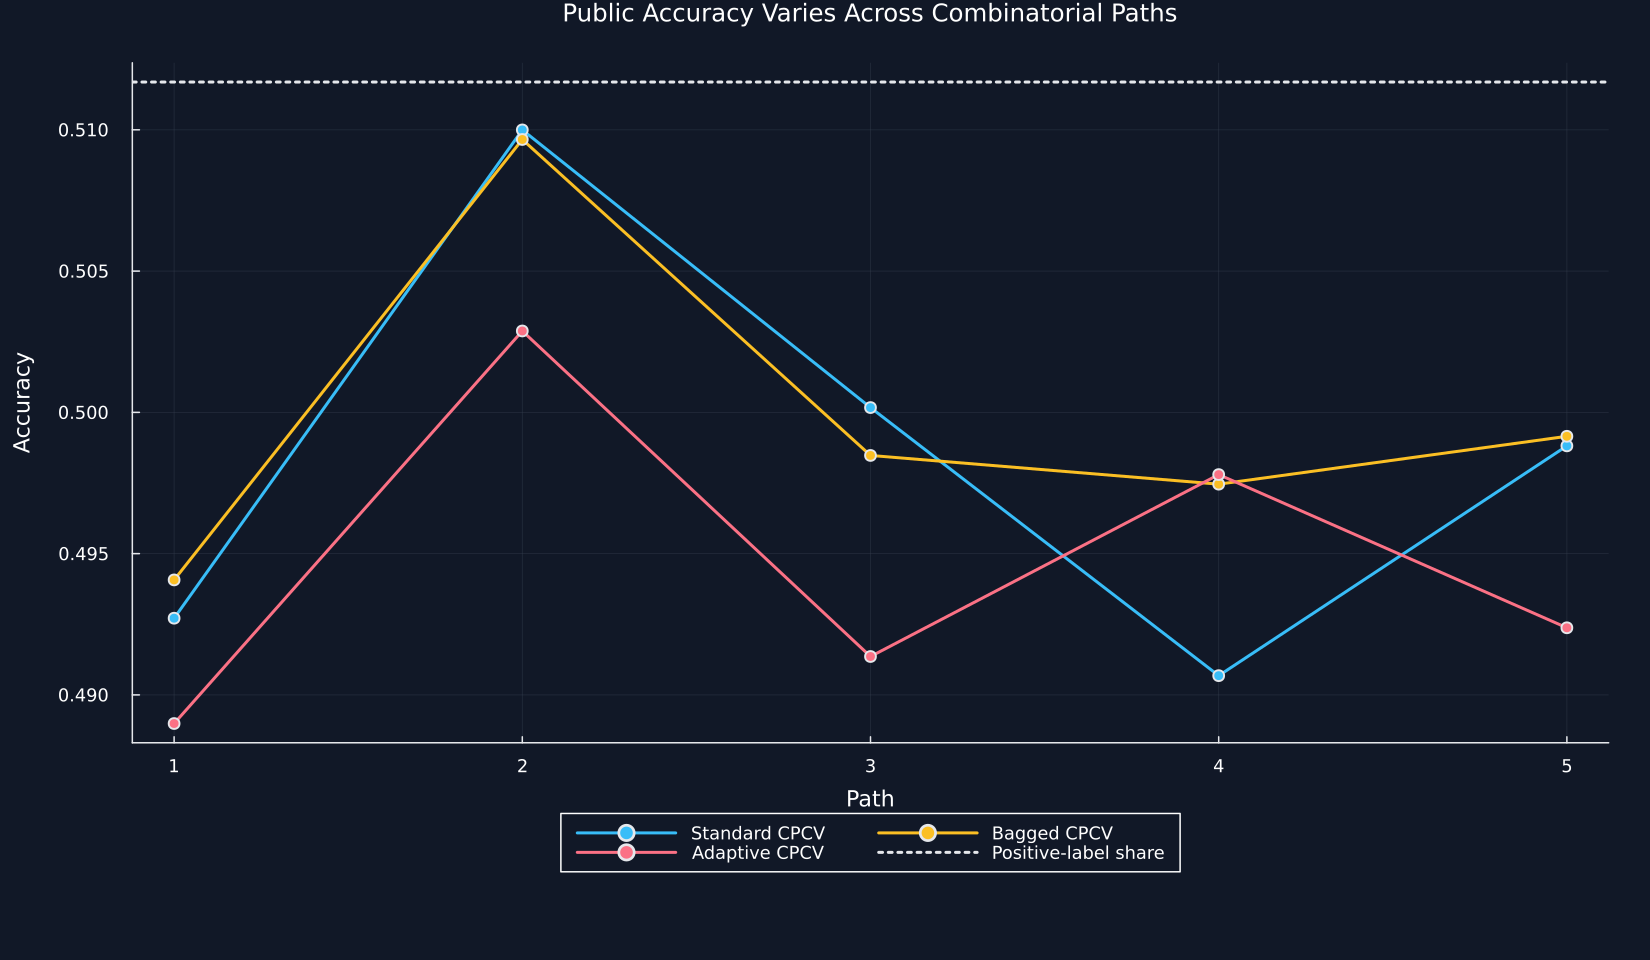

In [2]:
n_groups,n_test_groups,embargo_fraction = 6,2,.01
standard_validator = CombinatorialPurgedCV(n_groups,n_test_groups,dates,event_times;embargo=embargo_fraction)
bagged_validator = BaggedCombinatorialPurgedCV(n_groups,n_test_groups,dates,event_times;embargo=embargo_fraction,classifier=true,n_estimators=12,random_seed=15)
adaptive_validator = AdaptiveCombinatorialPurgedCV(n_groups,n_test_groups,dates,event_times;embargo=embargo_fraction,n_subsplits=3,external_feature,lower_quantile=.25,upper_quantile=.75,subtract_border_adjustments=true)
input_root = joinpath("..","data","chapter17_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
manifest = TOML.parsefile(manifest_path)
for (name,record) in manifest["files"]
end
draw_matrices = []
sample_indices = [[matrix[:,member] for member in 1:12] for matrix in draw_matrices]
feature_indices = [[collect(1:6) for member in 1:12] for split in 1:15]
seed_frame = CSV.read(joinpath(input_root,"member_seeds.csv"),DataFrame)
estimator_seeds = [seed_frame[seed_frame.split.==split,:seed] for split in 1:15]
@assert nrow(seed_frame)==180
standard_predictions,standard_models = fit_paths(standard_validator,"standard")
bagged_predictions,bagged_models = fit_paths(bagged_validator,"bagged";sample_indices,feature_indices,estimator_seeds)
adaptive_predictions,adaptive_models = fit_paths(adaptive_validator,"adaptive")
standard_path_accuracy = path_scores("Standard CPCV",standard_predictions)
bagged_path_accuracy = path_scores("Bagged CPCV",bagged_predictions)
adaptive_path_accuracy = path_scores("Adaptive CPCV",adaptive_predictions)
method_path_accuracy = vcat(standard_path_accuracy,bagged_path_accuracy,adaptive_path_accuracy)
method_accuracy_summary = combine(groupby(method_path_accuracy,:Method;sort=false),"Accuracy"=>mean=>"Mean accuracy","Accuracy"=>std=>"Accuracy spread","Accuracy"=>minimum=>"Minimum accuracy","Accuracy"=>maximum=>"Maximum accuracy")
table(standard_path_accuracy,"standard_path_accuracy","Accuracy and prediction balance across the five standard public-data paths.")
table(method_path_accuracy,"method_path_accuracy","Path-level public-data results for standard, bagged, and adaptive combinatorial validation.")
table(method_accuracy_summary,"method_accuracy_summary","Summary of public-data accuracy across five paths for each combinatorial method.")
figure = plot(;title="Public Accuracy Varies Across Combinatorial Paths",xlabel="Path",ylabel="Accuracy",xticks=1:5,size=(1100,640),legend=:outerbottom,legendcolumns=2)
for (method,color) in zip(["Standard CPCV","Bagged CPCV","Adaptive CPCV"],[palette.cyan,palette.amber,palette.rose])
    portion = method_path_accuracy[method_path_accuracy.Method.==method,:]
    plot!(figure,portion.Path,portion.Accuracy;marker=:circle,color,label=method)
end
hline!(figure,[mean(public_y)];color=palette.text,linestyle=:dot,label="Positive-label share")
save_figure(figure,paths,"method_path_accuracy")


## Bagging Within Each Split

A class prediction is obtained by thresholding the averaged probability:

$$
\widehat y_s(x)=\mathbf 1\!\left\{\widehat p_s(x)\geq\frac12\right\}.
$$

Here, $\widehat y_s(x)$ is the predicted class, $\widehat p_s(x)$ is the bagged probability for split $s$, $\tfrac12$ is the classification threshold, and $\mathbf 1\{\cdot\}$ is the indicator function.

## Moving Group Boundaries

The released adaptive rule moves a candidate boundary by one small block according to an external feature:

$$
b_j^*=b_j-\delta_j,
\qquad
\delta_j=
\begin{cases}
-1,&z_{b_j}<q_L,\\
0,&q_L\leq z_{b_j}\leq q_U,\\
1,&z_{b_j}>q_U.
\end{cases}
$$

Here, $b_j$ is candidate boundary $j$ measured in small blocks, $b_j^*$ is its adjusted position, $z_{b_j}$ is the external feature at that boundary, $q_L$ and $q_U$ are its lower and upper quantiles, and $\delta_j$ is the one-block adjustment used by the selected direction rule.

Row,Group,Standard observations,Adaptive observations,Standard begins,Adaptive begins,Adaptive volatility mean
,Int64,Int64,Int64,String,String,Float64
1,1,492,328,2021-01-01 04:15:00,2021-01-01 04:15:00,0.00579964
2,2,492,492,2021-01-06 07:15:00,2021-01-04 14:15:00,0.00737389
3,3,492,656,2021-01-11 10:15:00,2021-01-09 17:15:00,0.00891705
4,4,492,328,2021-01-16 13:15:00,2021-01-16 13:15:00,0.00539162
5,5,492,656,2021-01-21 16:15:00,2021-01-19 23:15:00,0.00579992
6,6,491,491,2021-01-26 19:15:00,2021-01-26 19:15:00,0.00687758


Row,Method,Groups,Test groups,Splits,Paths,Distinct group sizes,Fitted members per split
,String,Int64,Int64,Int64,Int64,Int64,Int64
1,Standard CPCV,6,2,15,5,2,1
2,Bagged CPCV,6,2,15,5,2,12
3,Adaptive CPCV,6,2,15,5,4,1


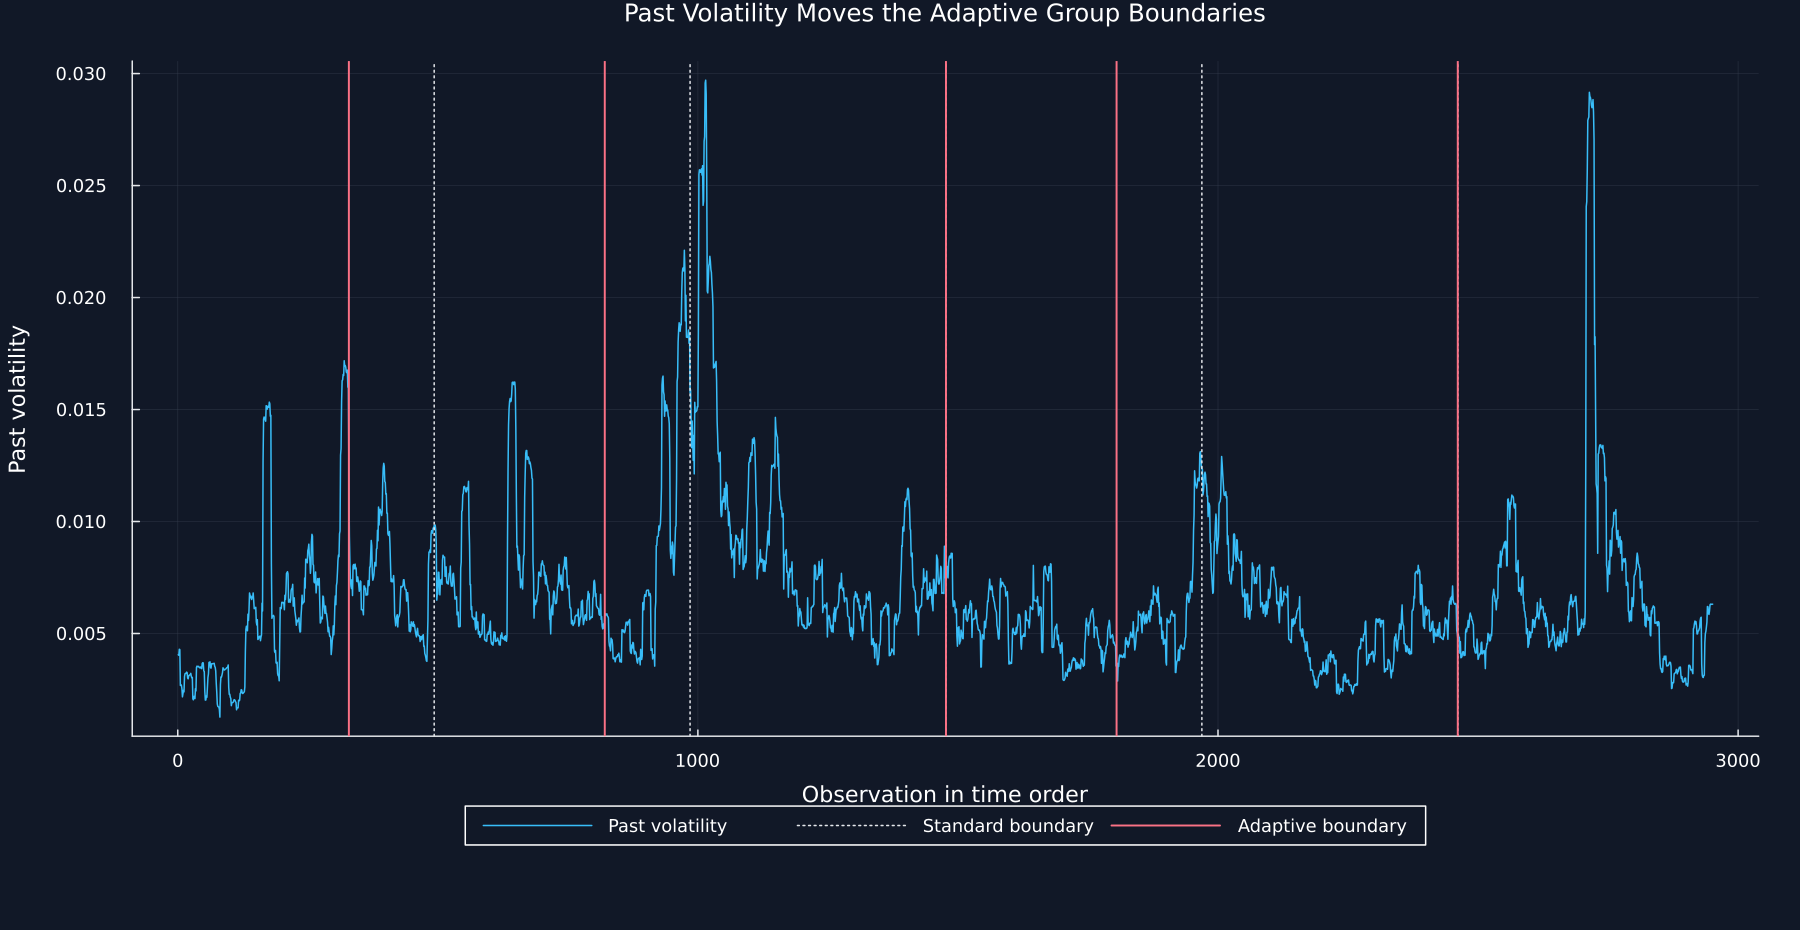

In [3]:
standard_segments = RiskLabAI.Validation._validation_segments(standard_validator)
adaptive_segments = RiskLabAI.Validation._validation_segments(adaptive_validator)
adaptive_records = NamedTuple[]
segment_evidence = DataFrame(position=collect(1:count_observations),volatility=external_feature,standard_group=zeros(Int,count_observations),adaptive_group=zeros(Int,count_observations))
for (group,(standard,adaptive)) in enumerate(zip(standard_segments,adaptive_segments))
    push!(adaptive_records,(group=group,standard=length(standard),adaptive=length(adaptive),standard_begins=format_time(dates[first(standard)]),adaptive_begins=format_time(dates[first(adaptive)]),volatility=mean(external_feature[adaptive])))
    segment_evidence.standard_group[standard] .= group
    segment_evidence.adaptive_group[adaptive] .= group
end
save_data(segment_evidence,paths,"adaptive_boundaries")
adaptive_group_summary = DataFrame(adaptive_records)
rename!(adaptive_group_summary,["Group","Standard observations","Adaptive observations","Standard begins","Adaptive begins","Adaptive volatility mean"])
table(adaptive_group_summary,"adaptive_group_summary","Standard and volatility-adjusted group sizes on the public data.")
method_structure_summary = DataFrame("Method"=>["Standard CPCV","Bagged CPCV","Adaptive CPCV"],"Groups"=>fill(n_groups,3),"Test groups"=>fill(n_test_groups,3),"Splits"=>get_n_splits.([standard_validator,bagged_validator,adaptive_validator]),"Paths"=>length.([standard_predictions,bagged_predictions,adaptive_predictions]),"Distinct group sizes"=>[length(unique(length.(standard_segments))),length(unique(length.(standard_segments))),length(unique(length.(adaptive_segments)))],"Fitted members per split"=>[1,bagged_validator.n_estimators,1])
table(method_structure_summary,"method_structure_summary","Structural comparison of the three released combinatorial methods used in the public experiment.")
figure = plot(1:count_observations,external_feature;color=palette.cyan,linewidth=1,label="Past volatility",xlabel="Observation in time order",ylabel="Past volatility",title="Past Volatility Moves the Adaptive Group Boundaries",size=(1200,620),legend=:outerbottom,legendcolumns=3)
vline!(figure,first.(standard_segments[2:end]);color=palette.text,linestyle=:dot,linewidth=1,label="Standard boundary")
vline!(figure,first.(adaptive_segments[2:end]);color=palette.rose,linewidth=1.3,label="Adaptive boundary")
save_figure(figure,paths,"adaptive_boundaries")


The reported mean and spread summarize the finite set of paths:

$$
\overline A_m=\frac{1}{\varphi}\sum_{p=1}^{\varphi}A_{m,p},
\qquad
s_m=\sqrt{\frac{1}{\varphi-1}\sum_{p=1}^{\varphi}(A_{m,p}-\overline A_m)^2}.
$$

Here, $m$ identifies a validation method, $p$ identifies a path, $\varphi$ is the number of paths, $A_{m,p}$ is path accuracy, $\overline A_m$ is mean path accuracy, and $s_m$ is its sample spread. These quantities describe this public sample and do not establish that one method is generally best.

## Tests

In [4]:
@assert length(standard_predictions)==5
@assert length(bagged_predictions)==5
@assert length(adaptive_predictions)==5
@assert all(length(values)==count_observations for values in values(standard_predictions))
@assert all(length(values)==count_observations for values in values(bagged_predictions))
@assert all(length(values)==count_observations for values in values(adaptive_predictions))
@assert all(all(value->value in (0,1),values) for values in values(standard_predictions))
@assert all(all(value->value in (0,1),values) for values in values(bagged_predictions))
@assert all(all(value->value in (0,1),values) for values in values(adaptive_predictions))
@assert size(standard_path_accuracy)==(5,6)
@assert size(method_path_accuracy)==(15,6)
@assert size(method_accuracy_summary)==(3,5)
@assert all(value->0<=value<=1,method_path_accuracy.Accuracy)
@assert sum(length,standard_segments)==count_observations
@assert sum(length,adaptive_segments)==count_observations
@assert length(unique(length.(standard_segments)))<=2
@assert length(unique(length.(adaptive_segments)))>1
@assert size(adaptive_group_summary)==(6,6)
@assert size(method_structure_summary)==(3,7)
@assert all(==(15),method_structure_summary.Splits)
@assert all(==(5),method_structure_summary.Paths)
@assert isfile(joinpath(paths.figures,"method_path_accuracy.pdf"))
@assert isfile(joinpath(paths.figures,"adaptive_boundaries.pdf"))
@assert isfile(joinpath(paths.tables,"standard_path_accuracy.tex"))
@assert isfile(joinpath(paths.tables,"method_path_accuracy.tex"))
@assert isfile(joinpath(paths.tables,"method_accuracy_summary.tex"))
@assert isfile(joinpath(paths.tables,"adaptive_group_summary.tex"))
@assert isfile(joinpath(paths.tables,"method_structure_summary.tex"))
